
# EXERCISES F: Datasets on Use


In [21]:
import numpy as np
import matplotlib.pyplot as plt

## 1 Reducing Dimensionality

### 1.1 Reducing 2D Artificial Datasets into 1D Datasets

Use the following 2D artificial dataset generator, and obtain various binary classification problems. Then:

1. Plot these 2D datasets.
2. Apply some classification technique to them, e.g., a logistic regression.
3. Evaluate and plot the result of the obtained classifiers.
4. Transform the dataset by PCA into 1D datasets (use `PCA` in `sklearn.decomposition`):
5. Apply the same classification technique to the obtained 1D datasets.
6. Evaluate and plot the result of the obtained classifiers.
7. Compare the two kinds of results (the ones in 2D vs. the ones in 1D).

    

In [22]:
import numpy as np
from numpy.random import Generator, PCG64

def generate_data(mean_A, mean_B, N_A, N_B, random_seed=42):
    # Initialize the random number generator with a seed for reproducibility
    rng = Generator(PCG64(random_seed))
    
    # Covariance matrices (assuming identity covariance)
    cov_A = np.identity(2)
    cov_B = np.identity(2)
    
    # Generate the multivariate normal samples for both sets
    X_A = rng.multivariate_normal(mean_A, cov_A, size=N_A)
    X_B = rng.multivariate_normal(mean_B, cov_B, size=N_B)
    
    X = np.concatenate((X_A, X_B))
    
    # Create the labels array: 0 for class A, 1 for class B
    Y = np.array([0] * N_A + [1] * N_B)
    
    return X, Y, X_A, X_B

mean_A = [5, 7]
mean_B = [3, 10]
N_A = 200
N_B = 200
X, Y, X_A, X_B = generate_data(mean_A, mean_B, N_A, N_B)

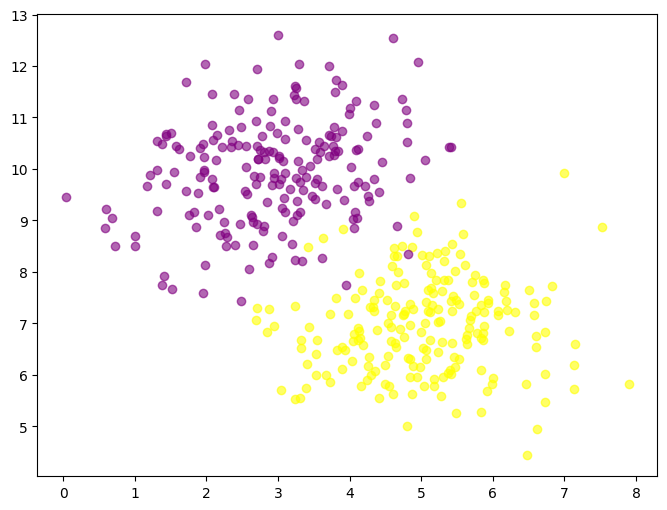

In [23]:
plt.figure(figsize=(8, 6))
plt.scatter(X_A[:, 0], X_A[:, 1], color='yellow', label='Class A', alpha=0.6)
plt.scatter(X_B[:, 0], X_B[:, 1], color='purple', label='Class B', alpha=0.6) 
plt.show()

In [24]:
from sklearn.decomposition import PCA

nb_components = 2
pca = PCA(n_components = nb_components)
X_pca = pca.fit_transform(X)
pca.explained_variance_ratio_

array([0.78610003, 0.21389997])

### Préparation des dataset

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# Plusieurs problèmes de classification binaire
problems = {
    "Bien séparé":  ([5, 7], [3, 10]),
    "Proches":      ([5, 7], [4, 8]),
    "Très proches": ([5, 7], [5.5, 7.5]),
}

datasets = {}
for name, (mA, mB) in problems.items():
    X, Y, X_A, X_B = generate_data(mA, mB, 200, 200)
    X_tr, X_te, Y_tr, Y_te = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=0)
    datasets[name] = dict(X=X, Y=Y, X_A=X_A, X_B=X_B,
                          X_tr=X_tr, X_te=X_te, Y_tr=Y_tr, Y_te=Y_te)

### 1. Tracer les jeux de données 2D

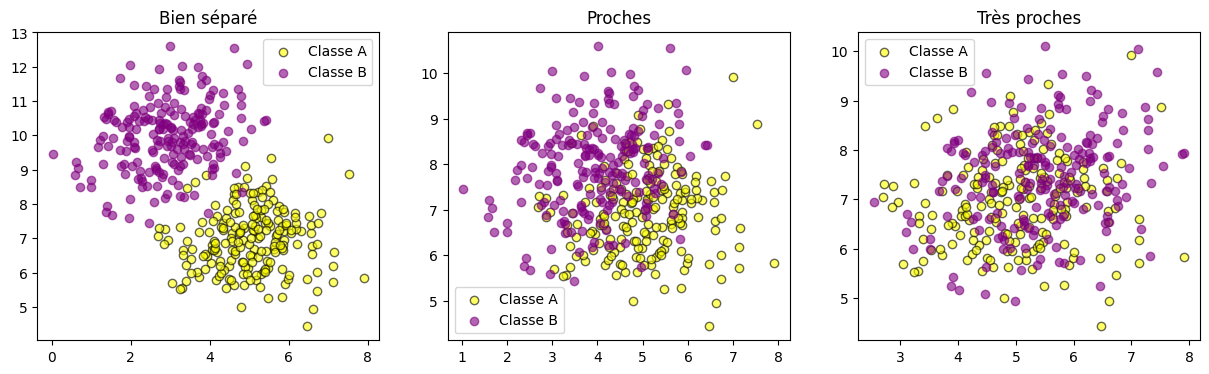

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, d) in zip(axes, datasets.items()):
    ax.scatter(d["X_A"][:, 0], d["X_A"][:, 1], color='yellow', edgecolor='k', label='Classe A', alpha=0.6)
    ax.scatter(d["X_B"][:, 0], d["X_B"][:, 1], color='purple', label='Classe B', alpha=0.6)
    ax.set_title(name); ax.legend()
plt.show()

### 2. Appliquer une régression logistique (2D)

In [27]:
for name, d in datasets.items():
    clf = LogisticRegression()
    clf.fit(d["X_tr"], d["Y_tr"])
    d["clf_2d"] = clf

### 3. Évaluer et tracer les classifieurs 2D

Bien séparé - accuracy 2D : 0.9833333333333333
[[59  1]
 [ 1 59]]
Proches - accuracy 2D : 0.7833333333333333
[[48 12]
 [14 46]]
Très proches - accuracy 2D : 0.65
[[41 19]
 [23 37]]


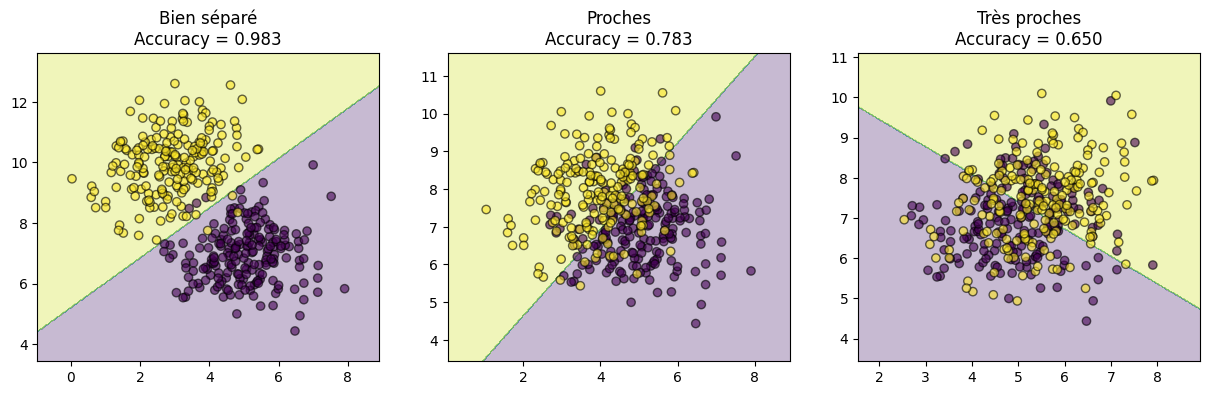

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, d) in zip(axes, datasets.items()):
    clf = d["clf_2d"]
    d["acc_2d"] = accuracy_score(d["Y_te"], clf.predict(d["X_te"]))
    print(name, "- accuracy 2D :", d["acc_2d"])
    print(confusion_matrix(d["Y_te"], clf.predict(d["X_te"])))

    # Frontière de décision
    x_min, x_max = d["X"][:, 0].min() - 1, d["X"][:, 0].max() + 1
    y_min, y_max = d["X"][:, 1].min() - 1, d["X"][:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    ax.scatter(d["X"][:, 0], d["X"][:, 1], c=d["Y"], cmap='viridis', edgecolor='k', alpha=0.6)
    ax.set_title(f"{name}\nAccuracy = {d['acc_2d']:.3f}")
plt.show()

### 4. Transformer en 1D par ACP

In [29]:
for name, d in datasets.items():
    pca = PCA(n_components=1)                    # 1 seule composante
    d["Z_tr"] = pca.fit_transform(d["X_tr"])     # on apprend l'ACP sur le train
    d["Z_te"] = pca.transform(d["X_te"])         # et on l'applique au test
    d["pca"] = pca
    print(name, "- variance expliquée :", pca.explained_variance_ratio_)

Bien séparé - variance expliquée : [0.78335451]
Proches - variance expliquée : [0.54224298]
Très proches - variance expliquée : [0.6092763]


### 5. Même classifieur sur les données 1D

In [30]:
for name, d in datasets.items():
    clf1 = LogisticRegression()
    clf1.fit(d["Z_tr"], d["Y_tr"])
    d["clf_1d"] = clf1

### 6. Évaluer et tracer les classifieurs 1D

Bien séparé - accuracy 1D : 0.9833333333333333
[[59  1]
 [ 1 59]]
Proches - accuracy 1D : 0.7666666666666667
[[47 13]
 [15 45]]
Très proches - accuracy 1D : 0.6166666666666667
[[39 21]
 [25 35]]


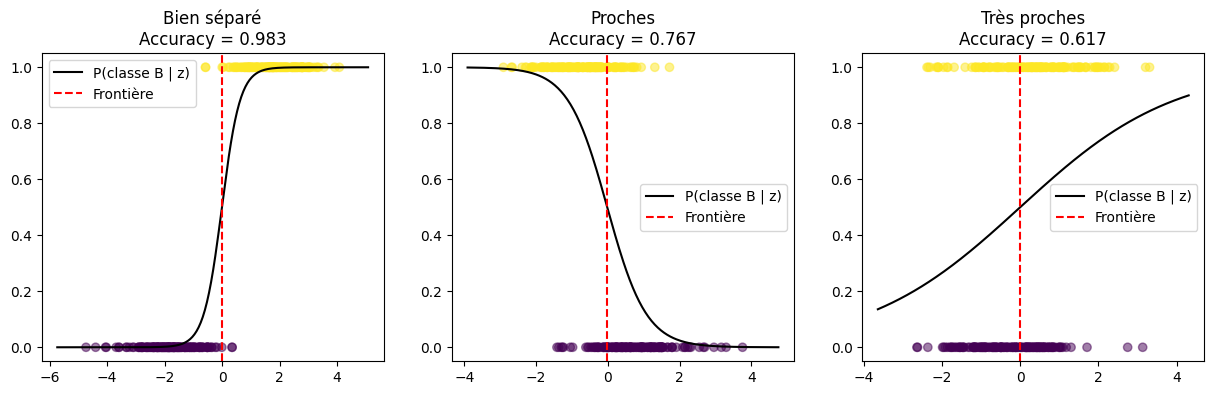

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, d) in zip(axes, datasets.items()):
    clf1 = d["clf_1d"]
    d["acc_1d"] = accuracy_score(d["Y_te"], clf1.predict(d["Z_te"]))
    print(name, "- accuracy 1D :", d["acc_1d"])
    print(confusion_matrix(d["Y_te"], clf1.predict(d["Z_te"])))

    # Points sur une droite + probabilité P(classe B) + seuil de décision
    z = np.linspace(d["Z_tr"].min() - 1, d["Z_tr"].max() + 1, 300).reshape(-1, 1)
    ax.plot(z, clf1.predict_proba(z)[:, 1], 'k-', label='P(classe B | z)')
    ax.scatter(d["Z_tr"], d["Y_tr"], c=d["Y_tr"], cmap='viridis', alpha=0.5)
    seuil = -clf1.intercept_[0] / clf1.coef_[0, 0]
    ax.axvline(seuil, color='r', linestyle='--', label='Frontière')
    ax.set_title(f"{name}\nAccuracy = {d['acc_1d']:.3f}")
    ax.legend()
plt.show()

### 7. Comparer 2D et 1D

In [32]:
print(f"{'Problème':<15}{'Acc. 2D':>10}{'Acc. 1D':>10}{'Var. expliquée':>18}")
for name, d in datasets.items():
    print(f"{name:<15}{d['acc_2d']:>10.3f}{d['acc_1d']:>10.3f}"
          f"{d['pca'].explained_variance_ratio_[0]:>18.3f}")

Problème          Acc. 2D   Acc. 1D    Var. expliquée
Bien séparé         0.983     0.983             0.783
Proches             0.783     0.767             0.542
Très proches        0.650     0.617             0.609


## Interprétation des résultats

### Tableau récapitulatif

| Problème     | Acc. 2D | Acc. 1D | Perte | Var. expliquée |
|--------------|---------|---------|-------|----------------|
| Bien séparé  | 0.983   | 0.983   | 0     | 0.783          |
| Proches      | 0.783   | 0.767   | −0.017 | 0.542         |
| Très proches | 0.650   | 0.617   | −0.033 | 0.609         |

### Classification en 2D

- **Bien séparé** : quasi parfait (1 erreur par classe sur 60). Les deux nuages sont distincts, une droite suffit.
- **Proches** : le chevauchement des classes provoque 26 erreurs sur 120 (12 + 14).
- **Très proches** : les classes sont presque confondues, 42 erreurs sur 120. Le classifieur est à peine meilleur que le hasard (0.50).

L'accuracy baisse donc logiquement quand la distance entre les moyennes diminue.

### Classification en 1D (après ACP)

- **Bien séparé** : aucune perte. La 1re composante (78 % de variance) correspond à la direction qui relie les deux classes, donc l'information utile est conservée. La matrice de confusion est identique à celle de la 2D.
- **Proches** : perte légère (−1,7 point). Seule 54 % de la variance est conservée, mais la réduction coûte peu.
- **Très proches** : perte plus nette (−3,3 points), la projection élimine une partie de l'information discriminante.

### Conclusion

1. Plus les classes sont proches, plus la classification est difficile, en 2D comme en 1D.
2. Passer de 2D à 1D ne dégrade pas ou peu les performances (écart ≤ 3,3 points), à condition que la direction de plus grande variance soit alignée avec la séparation des classes.
3. L'ACP maximise la variance, **pas la séparabilité** : la variance expliquée n'est pas un indicateur fiable de la qualité de classification. Le cas « Très proches » a plus de variance expliquée (0.609) que « Proches » (0.542) mais de moins bonnes performances.
4. Sur la visualisation 1D, la sigmoïde est très raide quand les classes sont séparées et devient plate quand elles se chevauchent (le classifieur est moins « sûr »).

### 1.2 Reducing the dimensionality of a true dataset
Let us work with the dataset "Optical recognition of handwritten digits dataset" directly available in `sklearn_datasets` (see originally https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits) which is a simpler alternative to MNIST:

In [33]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

data = load_digits()
X_train, X_test, Y_train, Y_test = train_test_split(data['data'], data['target'], test_size=0.2, random_state=43)

print(f'Number of training instances: {X_train.shape[0]}')
print(f'Initial number of dimensions: {X_train.shape[1]}')

Number of training instances: 1437
Initial number of dimensions: 64


Use again `sklearn.decomposition.PCA` to reduce the dimensionality of this dataset: 

1. Plot how this dimensionality reduction behaves depending on the number of chosen pca components and the ratio of explained variance (the sum of coefficients) against the number of dimensions (the number of coefficients).
2. Give what seems to be an appropriate range for the number of dimensions to use for PCA.

### Préparation (commune aux deux questions)

In [34]:
# ACP complète : on garde les 64 composantes pour pouvoir les étudier
pca = PCA().fit(X_train)
var_ratio = pca.explained_variance_ratio_   # variance de chaque composante
cumvar = np.cumsum(var_ratio)               # variance cumulée

### 1. tracer la variance expliquée en fonction du nombre de dimensions

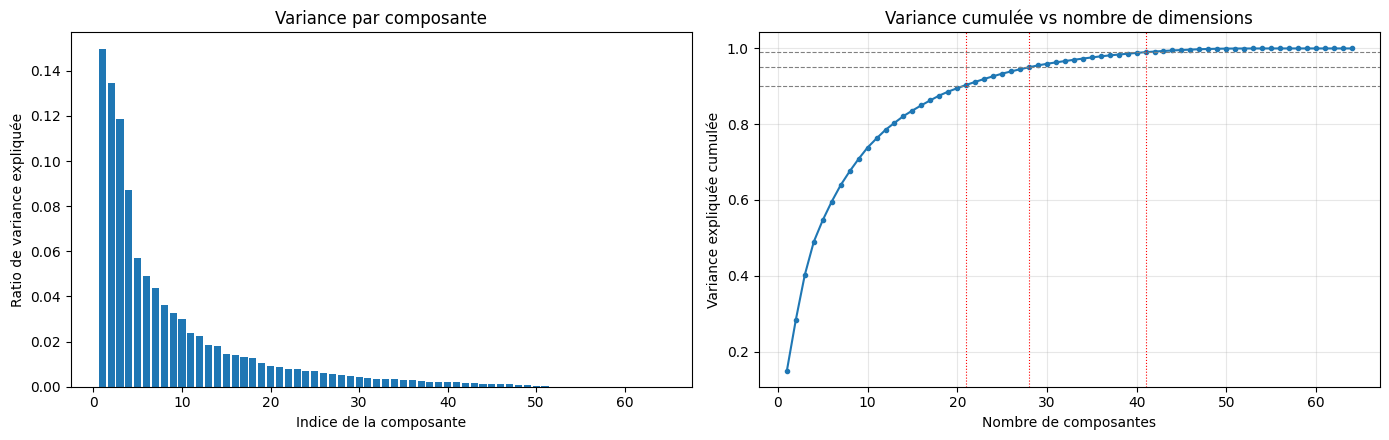

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Variance par composante
axes[0].bar(range(1, 65), var_ratio)
axes[0].set_xlabel("Indice de la composante")
axes[0].set_ylabel("Ratio de variance expliquée")
axes[0].set_title("Variance par composante")

# Variance cumulée (courbe demandée)
axes[1].plot(range(1, 65), cumvar, 'o-', markersize=3)
axes[1].set_xlabel("Nombre de composantes")
axes[1].set_ylabel("Variance expliquée cumulée")
axes[1].set_title("Variance cumulée vs nombre de dimensions")
axes[1].grid(alpha=0.3)

for seuil in [0.90, 0.95, 0.99]:
    k = np.argmax(cumvar >= seuil) + 1
    axes[1].axhline(seuil, color='gray', linestyle='--', linewidth=0.8)
    axes[1].axvline(k, color='r', linestyle=':', linewidth=0.8)
    
plt.tight_layout()
plt.show()

### 2. plage appropriée du nombre de dimensions

#### Étape A : lire les seuils sur la courbe

In [36]:
for seuil in [0.80, 0.90, 0.95, 0.99]:
    k = np.argmax(cumvar >= seuil) + 1
    print(f"{int(seuil*100)}% de variance : {k} composantes")

80% de variance : 13 composantes
90% de variance : 21 composantes
95% de variance : 28 composantes
99% de variance : 41 composantes


#### Étape B : vérifier avec les performances d’un classifieur

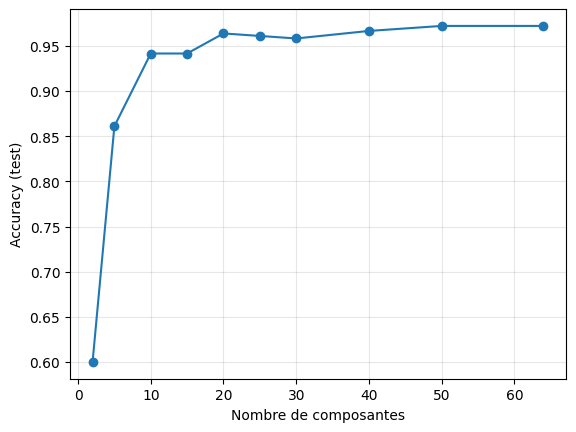

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

ks = [2, 5, 10, 15, 20, 25, 30, 40, 50, 64]
accs = []
for k in ks:
    p = PCA(n_components=k).fit(X_train)
    c = LogisticRegression(max_iter=5000).fit(p.transform(X_train), Y_train)
    accs.append(accuracy_score(Y_test, c.predict(p.transform(X_test))))

plt.plot(ks, accs, 'o-')
plt.xlabel("Nombre de composantes")
plt.ylabel("Accuracy (test)")
plt.grid(alpha=0.3)
plt.show()

## Interprétation des résultats

### Question 1 : variance expliquée

- **Variance par composante** : elle décroît très vite. Les 4 premières composantes ont chacune plus de 8 % de variance (la 1re ≈ 15 %), puis la courbe passe sous 2 % vers la 20e composante. Au-delà de la 50e, les composantes sont quasi nulles.
- **Variance cumulée** : la courbe monte rapidement puis s'aplatit. Seuils lus :

| Variance conservée | Composantes | % des 64 dimensions |
|--------------------|-------------|---------------------|
| 80 %               | 13          | 20 %                |
| 90 %               | 21          | 33 %                |
| 95 %               | 28          | 44 %                |
| 99 %               | 41          | 64 %                |

- **Rendements décroissants** : passer de 13 à 21 composantes (+8) apporte +10 points de variance, alors que passer de 28 à 41 (+13) n'en apporte que +4. Les pixels sont fortement corrélés entre eux, d'où la forte redondance.

### Question 2 : plage appropriée

L'accuracy sur le test confirme la lecture de la variance :

- **2 → 10 composantes** : forte progression (0.60 → 0.94).
- **≈ 20 composantes** : l'accuracy atteint ≈ 0.96, soit presque le niveau des 64 dimensions (≈ 0.97).
- **> 20 composantes** : plateau, les composantes supplémentaires n'apportent pratiquement rien.

**Plage retenue : environ 20 à 30 composantes** (90 à 95 % de variance), ce qui divise la dimension par 2 à 3 pour une perte d'accuracy inférieure à 1 point. Avec 41 composantes (99 %), on conserve plus que nécessaire.

### Remarques

- Le choix dépend du compromis voulu : **~13 composantes** si on accepte de perdre un peu de performance pour compresser davantage, **~28** si on privilégie la fidélité.
- La variance expliquée mesure la fidélité de la reconstruction, pas directement la qualité de classification. Ici les deux sont bien alignées, ce qui n'est pas garanti en général.
- Le test porte sur 360 images : des écarts de 1 point (≈ 3 images) restent dans le bruit statistique.

## 2. Binary classification over a text dataset

Here, the dataset is made of texts corresponding to reviews of movies from the IMDB site. The binary classification problem is to separate them into positive and negative reviews. 

(This exercise/example is taken from Chollet 2021, Chapter 4)

### 2.1 Load and explore the dataset

Use the code below to download the classic IMDB dataset from `Tensorflow`.

N.B.: Warnings may occur from Tensorflow if not installed, but with no impact to the effective load of the dataset.

In [38]:
from tensorflow.keras.datasets import imdb
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [39]:
train_data.shape, test_data.shape

((25000,), (25000,))

The texts are represented into word occurrences which are encoded by their respective frequency
(the '10000' appearing above indicates that only the 10000 most frequent words are on use)

In [40]:
#print the first sample of the dataset:
train_data[0]

[1,
 14,
 22,
 16,
 43,
 530,
 973,
 1622,
 1385,
 65,
 458,
 4468,
 66,
 3941,
 4,
 173,
 36,
 256,
 5,
 25,
 100,
 43,
 838,
 112,
 50,
 670,
 2,
 9,
 35,
 480,
 284,
 5,
 150,
 4,
 172,
 112,
 167,
 2,
 336,
 385,
 39,
 4,
 172,
 4536,
 1111,
 17,
 546,
 38,
 13,
 447,
 4,
 192,
 50,
 16,
 6,
 147,
 2025,
 19,
 14,
 22,
 4,
 1920,
 4613,
 469,
 4,
 22,
 71,
 87,
 12,
 16,
 43,
 530,
 38,
 76,
 15,
 13,
 1247,
 4,
 22,
 17,
 515,
 17,
 12,
 16,
 626,
 18,
 2,
 5,
 62,
 386,
 12,
 8,
 316,
 8,
 106,
 5,
 4,
 2223,
 5244,
 16,
 480,
 66,
 3785,
 33,
 4,
 130,
 12,
 16,
 38,
 619,
 5,
 25,
 124,
 51,
 36,
 135,
 48,
 25,
 1415,
 33,
 6,
 22,
 12,
 215,
 28,
 77,
 52,
 5,
 14,
 407,
 16,
 82,
 2,
 8,
 4,
 107,
 117,
 5952,
 15,
 256,
 4,
 2,
 7,
 3766,
 5,
 723,
 36,
 71,
 43,
 530,
 476,
 26,
 400,
 317,
 46,
 7,
 4,
 2,
 1029,
 13,
 104,
 88,
 4,
 381,
 15,
 297,
 98,
 32,
 2071,
 56,
 26,
 141,
 6,
 194,
 7486,
 18,
 4,
 226,
 22,
 21,
 134,
 476,
 26,
 480,
 5,
 144,
 30,
 5535,
 18,

In [41]:
#labeling is 0: negative review;  1: positive review 
train_labels[0]

np.int64(1)

It is possible to decode the reviews back into text by using the associated dictionary:

In [42]:
word_index = imdb.get_word_index()
word_index

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


{'fawn': 34701,
 'tsukino': 52006,
 'nunnery': 52007,
 'sonja': 16816,
 'vani': 63951,
 'woods': 1408,
 'spiders': 16115,
 'hanging': 2345,
 'woody': 2289,
 'trawling': 52008,
 "hold's": 52009,
 'comically': 11307,
 'localized': 40830,
 'disobeying': 30568,
 "'royale": 52010,
 "harpo's": 40831,
 'canet': 52011,
 'aileen': 19313,
 'acurately': 52012,
 "diplomat's": 52013,
 'rickman': 25242,
 'arranged': 6746,
 'rumbustious': 52014,
 'familiarness': 52015,
 "spider'": 52016,
 'hahahah': 68804,
 "wood'": 52017,
 'transvestism': 40833,
 "hangin'": 34702,
 'bringing': 2338,
 'seamier': 40834,
 'wooded': 34703,
 'bravora': 52018,
 'grueling': 16817,
 'wooden': 1636,
 'wednesday': 16818,
 "'prix": 52019,
 'altagracia': 34704,
 'circuitry': 52020,
 'crotch': 11585,
 'busybody': 57766,
 "tart'n'tangy": 52021,
 'burgade': 14129,
 'thrace': 52023,
 "tom's": 11038,
 'snuggles': 52025,
 'francesco': 29114,
 'complainers': 52027,
 'templarios': 52125,
 '272': 40835,
 '273': 52028,
 'zaniacs': 52130,

In [43]:
reverse_word_index = dict(
    [(value, key) for (key, value) in word_index.items()])
reverse_word_index

{34701: 'fawn',
 52006: 'tsukino',
 52007: 'nunnery',
 16816: 'sonja',
 63951: 'vani',
 1408: 'woods',
 16115: 'spiders',
 2345: 'hanging',
 2289: 'woody',
 52008: 'trawling',
 52009: "hold's",
 11307: 'comically',
 40830: 'localized',
 30568: 'disobeying',
 52010: "'royale",
 40831: "harpo's",
 52011: 'canet',
 19313: 'aileen',
 52012: 'acurately',
 52013: "diplomat's",
 25242: 'rickman',
 6746: 'arranged',
 52014: 'rumbustious',
 52015: 'familiarness',
 52016: "spider'",
 68804: 'hahahah',
 52017: "wood'",
 40833: 'transvestism',
 34702: "hangin'",
 2338: 'bringing',
 40834: 'seamier',
 34703: 'wooded',
 52018: 'bravora',
 16817: 'grueling',
 1636: 'wooden',
 16818: 'wednesday',
 52019: "'prix",
 34704: 'altagracia',
 52020: 'circuitry',
 11585: 'crotch',
 57766: 'busybody',
 52021: "tart'n'tangy",
 14129: 'burgade',
 52023: 'thrace',
 11038: "tom's",
 52025: 'snuggles',
 29114: 'francesco',
 52027: 'complainers',
 52125: 'templarios',
 40835: '272',
 52028: '273',
 52130: 'zaniacs',

In [44]:
reverse_word_index.get(34701)  

'fawn'

In [45]:
reverse_word_index.get(2)  

'and'

In [46]:
# Here is what happens when the code does not exist:
reverse_word_index.get(10000000, "?")  

'?'

In [47]:
# Here is the decoding of the first sample: 
decoded_review = " ".join(
    [reverse_word_index.get(i - 3, "?") for i in train_data[0]])
decoded_review

"? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also ? to the two little boy's that played the ? of norman and paul they were just brilliant children are often left out of the ? list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done don't you th

In [48]:
data = [1,14,22,14]
decoded_review = " ".join(
    [reverse_word_index.get(i - 3, "?") for i in data])
decoded_review

'? this film this'

### 2.2 Vectorization the dataset 
As seen in the course, using a dictionary is not an adequate representation for most ML techniques. 
It is better to vectorize the word occurrences into binary arrays.

In [49]:
import numpy as np
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        for j in sequence:
            results[i, j] = 1.
    return results
    
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")

In [50]:
x_train[0], y_train[0]

(array([0., 1., 1., ..., 0., 0., 0.], shape=(10000,)), np.float32(1.0))

### 3.3 Obtain a generalization/model  
Use the above vectorized dataset and train a simple binary classifier over it.

N.B.: Without Tensorflow, it can take some time, but not so much, e.g., with `SGDClassifier`.

### 3.4 Evaluate the obtained generalization/model

- Try and observe the predictions of the classifer on some single data.
- Use the whole test dataset to evaluate the classifier.
- Plot the confusion matrix, and observe the error cases.
- Try to improve the classifier.
 